In [16]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay



# Reading the data
rawdata = pd.read_csv('./academic-performance-prediction/2023YRBS.csv', 
                 sep=';',
                dtype='string')


# The feature questions
questions = ['q41','q42','q43','q48','q49'
             ,'q50','q51','q52','q53','q54'
             ,'q55','q85','q26','q84','q76'
             ,'q1','q2','q3','q87']

# Filtered dataframe with our questions without NA values
df = rawdata[questions].dropna()

In [17]:
# Renaming the columns so they can be distinguished easily
df = df.rename(columns = {
    'q41':'Lifetime alcohol use',
    'q42':'Current alcohol use',
    'q43':'Binge drinking',
    'q48':'Current marijuana use',
    'q49':'Prescription pain medicine use',
    'q50':'Cocaine use',
    'q51':'Inhalants use',
    'q52':'Heroin use',
    'q53':'Methamphetamine use',
    'q54':'Ecstacy/MDMA use',
    'q55':'Injected illegal drugs',
    'q85':'Sleep duration',
    'q26':'Mental health indicators (feeling hopeless/sad)',
    'q84':'Mental health indicators (anxiety/depression)',
    'q76':'Physical activity',
    'q1':'Age',
    'q2':'Sex',
    'q3':'Grade level',
    'q87':'Grades past 12 months'
    })

# Changing data type to integers
df = df.astype(int)

In [18]:
# Lifetime alchol use 1 if ever used 0 if never
df['Lifetime alcohol use'] = (df['Lifetime alcohol use'] != 1).astype(int)

# Current alcohol use past 30 days, if 0 days then 0 else 1
df['Current alcohol use'] = (df['Current alcohol use'] != 1).astype(int)

# Binge drinking past 30 days, if 0 days then 0 else 1
df['Binge drinking'] = (df['Binge drinking'] != 1).astype(int)

# Current marijuana use past 30 days, if 0 days then 0 else 1
df['Current marijuana use'] = (df['Current marijuana use'] != 1).astype(int)

# Prescription pain medicine/cocaine/inhalants/heroin/methamphetamine/MDMA/injected illegal drugs
# lifitime use 0 if never 1 if ever
df['Prescription pain medicine use'] = (df['Prescription pain medicine use'] != 1).astype(int)
df['Cocaine use'] = (df['Cocaine use'] != 1).astype(int)
df['Inhalants use'] = (df['Inhalants use'] != 1).astype(int)
df['Heroin use'] = (df['Heroin use'] != 1).astype(int)
df['Methamphetamine use'] = (df['Methamphetamine use'] != 1).astype(int)
df['Ecstacy/MDMA use'] = (df['Ecstacy/MDMA use'] != 1).astype(int)
df['Injected illegal drugs'] = (df['Injected illegal drugs'] != 1).astype(int)

# Exclude not sure and missing values (6 or 7)
df = df[df['Grades past 12 months'].isin([1,2,3,4,5])].copy()

# Grade classes 1 if mostly A/B 0 if mostly C/D/F
df['Grade_class_target'] = (df['Grades past 12 months'] <= 2).astype(int)


In [19]:
# Used for both models
X = df.drop(columns=['Grade_class_target','Grades past 12 months'])
y = df['Grade_class_target']

# Splitting the data
# Training data = 70%
X_train, X_temp, y_train, y_temp = train_test_split(
    X,y, test_size = 0.30, random_state = 42, stratify=y
)

# Test data = 15% , validation data = 15% (both half of 30)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,y_temp, test_size = 0.50, random_state = 42, stratify=y_temp
)

In [20]:
# Method 1. Logistic regression 

# Fitting a classifier to the training set using logistic regression
clf_logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
clf_logreg.fit(X_train, y_train)

# Prediciting the training set labels
y_pred_train_logreg = clf_logreg.predict(X_train)
y_pred_val_logreg = clf_logreg.predict(X_val)

# The training accuracy
training_accuracy_logreg = accuracy_score(y_train, y_pred_train_logreg)

# Predicting validation set labels
validation_accuracy_logreg = accuracy_score(y_val,y_pred_val_logreg)

In [21]:
# Method 2. Decision Tree

# Finding best depth for the DT so that validation is the lowest
val_accs = []
val_depths = []
for depth in range(2, 20, 2):
    tree = clf_dectree = DecisionTreeClassifier(
    criterion="gini", 
    max_depth=depth,
    random_state=42
    )
    tree.fit(X_train, y_train)
    
    val_acc = accuracy_score(y_val, tree.predict(X_val))
    val_accs.append(val_acc)
    val_depths.append(depth)

# We get the depth with highest validation accuracy 
depth = val_depths[val_accs.index(max(val_accs))]


clf_dectree = DecisionTreeClassifier(
    criterion="entropy", 
    max_depth=depth,
    random_state=42
)
clf_dectree.fit(X_train, y_train)

y_pred_train_dectree = clf_dectree.predict(X_train)
y_pred_val_dectree = clf_dectree.predict(X_val)


training_accuracy_dectree = accuracy_score(y_train,y_pred_train_dectree)
validation_accuracy_dectree = accuracy_score(y_val,y_pred_val_dectree)

Logistic regression
Training accuracy: 0.7526727301739269
Validation accuracy: 0.7483246463142219
Test accuracy: 0.7505584512285927 

Decision tree
Training accuracy: 0.7502792404659326
Validation accuracy: 0.7453462397617274
Test accuracy: 0.7408786299329858


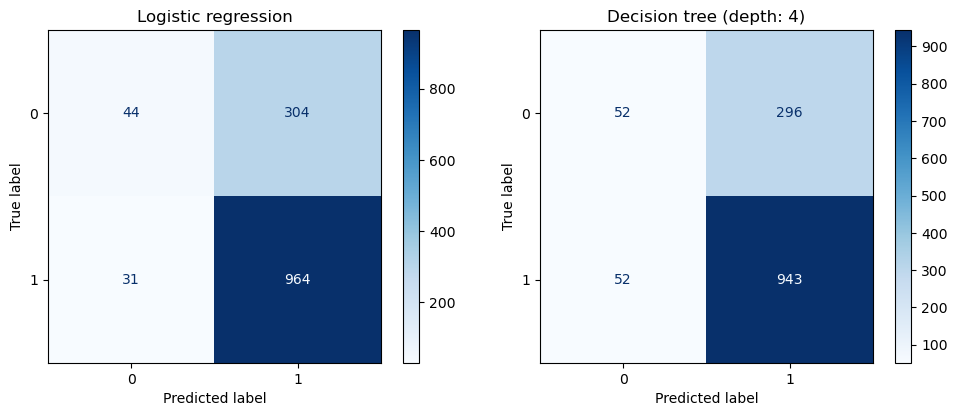

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Logistic regression

print("Logistic regression")
print(f"Training accuracy: {training_accuracy_logreg}")
print(f"Validation accuracy: {validation_accuracy_logreg}")

# Test accuracy
y_pred_test_logreg = clf_logreg.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_test_logreg)} \n")

# Logreg confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_logreg, ax=axes[0], cmap="Blues"
)
axes[0].set_title("Logistic regression")

# Descision tree

print("Decision tree")
print(f"Training accuracy: {training_accuracy_dectree}")
print(f"Validation accuracy: {validation_accuracy_dectree}")

# Test accuracy
y_pred_test_dectree = clf_dectree.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test ,y_pred_test_dectree)}")

# Dectree confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test_dectree, ax=axes[1], cmap="Blues"
)
axes[1].set_title(f"Decision tree (depth: {depth})")

plt.tight_layout()
plt.show()